# 📊 模組活動二｜AI 輔助 EDA 與視覺化
### 把抓回來的 JSON/CSV 洗成乾淨的結構化資料，再讓 AI 畫出折線圖與散佈圖
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rlirdo/envchem-ai-module-kit/blob/main/notebooks/M2_clean_visualize.ipynb)　｜　[懶人包網站](https://rlirdo.github.io/envchem-ai-module-kit/)　｜　[本模組操作手冊](https://rlirdo.github.io/envchem-ai-module-kit/m2.html)　｜　[Prompt 指南](https://rlirdo.github.io/envchem-ai-module-kit/prompts.html)

| 步驟 | 你要做的事 | 成功的樣子 |
|---|---|---|
| 1 | 載入資料（自己的 CSV 或離線備援包） | `df.info()` 看到約 700 列 |
| 2 | 盤點無效值 → Prompt 清洗 → 算統計 | 平均／最大／最小值表 |
| 3 | 結構化：時間欄、小時欄、存乾淨 CSV | `hour` 欄出現 |
| 4 | 中文字型 → 折線圖 → 散佈圖 | 兩張圖都有中文標題 |
| 5 | 圖表優化與時空分析 | 回答「O₃ 幾點最高？為什麼？」 |

> 📌 先寫 Prompt 給 AI，**卡關 5 分鐘**再展開參考解答。圖要「經過你校正」才算數：標題、軸標籤、單位、圖例都要對。

<sub>NDHU 自資系 游豐兆 博士生製作｜指導教授 楊悠娟 副教授｜國立東華大學 115-1 環境化學 × 生成式 AI 融入專業課程計畫</sub>

## 步驟 1｜載入資料
- **用自己上週的 CSV**：執行下面第一格會跳出「選擇檔案」。
- **上週沒抓到**：直接用懶人包的**離線備援包**（花蓮站真實資料 20260917～20261017）。

In [1]:
# 載入懶人包的「環境部 API 常用代碼庫」（只做一次）
import os, urllib.request
if not os.path.exists('moenv_api.py'):
    urllib.request.urlretrieve('https://rlirdo.github.io/envchem-ai-module-kit/moenv_api.py', 'moenv_api.py')
import moenv_api as ma
import pandas as pd
print('✅ 代碼庫已載入：', list(ma.DATASETS))

✅ 代碼庫已載入： ['aqx_p_432', 'aqx_p_488', 'aqx_p_13', 'aqx_p_07']


In [2]:
USE_BACKUP = True      # 想用自己的 CSV，改成 False 再執行
if USE_BACKUP:
    df = pd.read_csv('https://raw.githubusercontent.com/rlirdo/envchem-ai-module-kit/main/data/hualien_aqx_p_488_hourly_20260917_20261017.csv', dtype=str)
else:
    from google.colab import files
    up = files.upload()                       # 選擇上週下載的 CSV
    df = pd.read_csv(list(up)[0], dtype=str)
print(len(df), '列 ×', df.shape[1], '欄')
df.info()

718 列 × 25 欄
<class 'pandas.DataFrame'>
RangeIndex: 718 entries, 0 to 717
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   sitename          718 non-null    str  
 1   county            718 non-null    str  
 2   aqi               718 non-null    str  
 3   pollutant         61 non-null     str  
 4   status            718 non-null    str  
 5   so2               711 non-null    str  
 6   so2_avg           718 non-null    str  
 7   co                713 non-null    str  
 8   co_8hr            718 non-null    str  
 9   o3                712 non-null    str  
 10  o3_8hr            718 non-null    str  
 11  pm10              713 non-null    str  
 12  pm10_avg          718 non-null    str  
 13  pm2.5             713 non-null    str  
 14  pm2.5_avg         718 non-null    str  
 15  no2               710 non-null    str  
 16  nox               710 non-null    str  
 17  no                710 non-null   

## 步驟 2｜數據清洗：先「看」再「洗」
真實資料的無效值不一定是 -999！先請 AI 幫你**盤點**：
```
我的 DataFrame 叫 df，欄位都是文字。請幫我寫 Python 程式碼，
檢查 o3、no2、nox、pm2.5 這幾欄裡，有哪些「不是數字」的值（例如空白、x、-999、ND），各出現幾次。
```

In [3]:
# ⬇️ AI 生成的盤點程式碼放這裡

In [4]:
#@title 🔑 參考解答：盤點無效值
import re
for c in ['o3', 'no2', 'nox', 'pm2.5']:
    s = df[c].astype(str).str.strip()
    bad = s[~s.str.fullmatch(r'-?\d+(\.\d+)?')]
    print(f'{c:6s} 非數字 {len(bad):3d} 筆：', dict(bad.value_counts()) if len(bad) else '無')

o3     非數字   6 筆： {}
no2    非數字   8 筆： {}
nox    非數字   8 筆： {}
pm2.5  非數字   5 筆： {}


接著清洗＋算統計（這是申請書裡的範例 Prompt，記得把你盤點到的無效值寫進去）：
```
我的環境數據中，有些數值是 -999、空白或 x，這代表無效值。請幫我寫 Python 程式碼，
把這些無效值剔除，並計算 PM2.5 和 O3 的平均值、最大值與最小值。
```

In [5]:
# ⬇️ AI 生成的清洗程式碼放這裡

In [6]:
#@title 🔑 參考解答：清洗並算平均／最大／最小
num_cols = ['aqi', 'so2', 'co', 'o3', 'pm10', 'pm2.5', 'no2', 'nox', 'no', 'windspeed', 'winddirec']
clean, removed = ma.clean_numeric(df, num_cols)
print('各欄被換成空值（NaN）的筆數：', removed)
clean[['pm2.5', 'o3']].agg(['mean', 'max', 'min']).round(1)

各欄被換成空值（NaN）的筆數： {'aqi': 0, 'so2': 7, 'co': 5, 'o3': 6, 'pm10': 5, 'pm2.5': 5, 'no2': 8, 'nox': 8, 'no': 8, 'windspeed': 0, 'winddirec': 0}


,pm2.5,o3
mean,8.6,34.7
max,31.0,82.0
min,0.0,8.0


## 步驟 3｜結構化：時間欄、小時欄、存成乾淨的 CSV
```
請把 clean 的 datacreationdate 轉成日期時間格式，新增一欄 hour（0–23 點），
依時間排序，再存成 hualien_clean.csv（utf-8-sig）。
```

In [7]:
# ⬇️ AI 生成的程式碼放這裡

In [8]:
#@title 🔑 參考解答：時間欄＋小時欄＋存檔
clean['datacreationdate'] = pd.to_datetime(clean['datacreationdate'])
clean = clean.sort_values('datacreationdate').reset_index(drop=True)
clean['hour'] = clean['datacreationdate'].dt.hour
clean.to_csv('hualien_clean.csv', index=False, encoding='utf-8-sig')
clean[['datacreationdate', 'hour', 'pm2.5', 'o3', 'no2', 'nox']].head()

,datacreationdate,hour,pm2.5,o3,no2,nox
0,2026-09-17 18:00:00,18,8.0,47.0,3.0,4.2
1,2026-09-17 19:00:00,19,12.0,46.0,4.0,5.3
2,2026-09-17 20:00:00,20,13.0,39.0,6.0,7.0
3,2026-09-17 21:00:00,21,12.0,33.0,5.0,6.5
4,2026-09-17 22:00:00,22,7.0,32.0,4.0,5.0


## 步驟 4｜視覺化
### 4-1 先讓圖可以顯示中文（只做一次）

In [9]:
#@title ▶ 執行：設定中文字型
ma.use_chinese_font()        # 下載思源黑體並設定給 matplotlib（約 10 秒）
print('✅ 中文字型已設定')

✅ 中文字型已設定


### 4-2 折線圖：一天 24 小時的 PM2.5 與 O₃（申請書範例 Prompt）
```
請幫我寫 Colab 程式碼，使用 matplotlib 或 seaborn 畫出一張折線圖。
X 軸是時間（一天 24 小時），Y 軸同時畫出 PM2.5 與 O3 的濃度變化，並用不同顏色區分。
請確保圖表標題與標籤可以顯示中文。資料用 clean 裡最近一個晴天（例如 O3 最高的那天）。
```
**改良版（補上任務、字型、單位、驗證）**：
```
【任務】我想看花蓮站 O3 最高那一天，PM2.5 與 O3 在 24 小時內怎麼變化。
【資料】clean 這個 DataFrame，欄位 datacreationdate、hour、pm2.5、o3（已是數字）。
【輸出】折線圖：X 軸 0–23 時，Y 軸 PM2.5（μg/m³）與 O3（ppb），不同顏色，標題寫測站與日期，存成 fig1_一天24小時.png。
【限制】請處理 Colab 中文字型（先執行 ma.use_chinese_font()，避免中文變成方塊 □□□）；化學式寫 O3、PM2.5，不用下標字元。
【驗證】畫圖前先印出這一天的 24 筆資料讓我確認，並說明每段程式在做什麼。
```

In [10]:
# ⬇️ AI 生成的折線圖程式碼放這裡

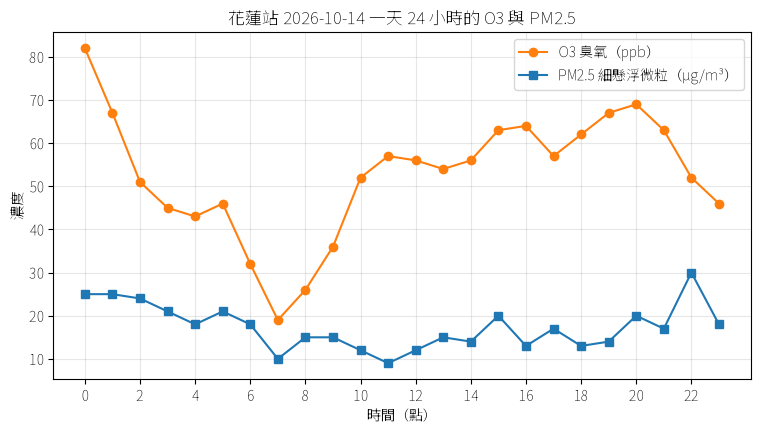

In [11]:
#@title 🔑 參考解答：24 小時折線圖
import matplotlib.pyplot as plt
day = clean.loc[clean['o3'].idxmax(), 'datacreationdate'].normalize()        # O3 最高的那一天
d1 = clean[clean['datacreationdate'].dt.normalize() == day]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(d1['hour'], d1['o3'], 'o-', color='tab:orange', label='O3 臭氧（ppb）')
ax.plot(d1['hour'], d1['pm2.5'], 's-', color='tab:blue', label='PM2.5 細懸浮微粒（μg/m³）')
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('時間（點）'); ax.set_ylabel('濃度')
ax.set_title(f'花蓮站 {day:%Y-%m-%d} 一天 24 小時的 O3 與 PM2.5')
ax.legend(); ax.grid(alpha=.3)
plt.savefig('fig1_一天24小時.png', dpi=200, bbox_inches='tight'); plt.show()

### 4-3 散佈圖：NOx 與 O₃ 的關係
```
請用 clean 畫一張散佈圖：X 軸是 NOx（ppb），Y 軸是 O3（ppb），點的顏色代表 hour（0–23 點），
加上色條、中文標題，並計算兩者的相關係數 r 顯示在標題上。
```

In [12]:
# ⬇️ AI 生成的散佈圖程式碼放這裡

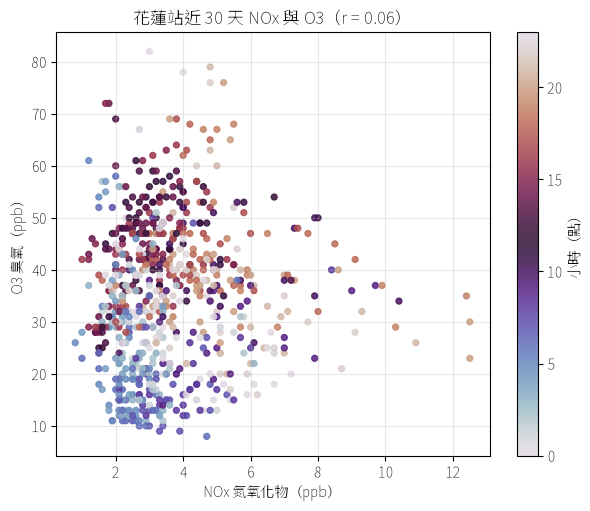

In [13]:
#@title 🔑 參考解答：NOx–O3 散佈圖
r = clean[['nox', 'o3']].corr().iloc[0, 1]
fig, ax = plt.subplots(figsize=(7, 5.5))
sc = ax.scatter(clean['nox'], clean['o3'], c=clean['hour'], cmap='twilight', s=18, alpha=.85)
plt.colorbar(sc, label='小時（點）')
ax.set_xlabel('NOx 氮氧化物（ppb）'); ax.set_ylabel('O3 臭氧（ppb）')
ax.set_title(f'花蓮站近 30 天 NOx 與 O3（r = {r:.2f}）')
ax.grid(alpha=.3)
plt.savefig('fig2_NOx_O3散佈圖.png', dpi=200, bbox_inches='tight'); plt.show()

### 4-4 加碼：30 天平均的「日變化」（雙軸圖）
```
請把 clean 依 hour 分組，算出每個小時 O3、NO2 的平均值，
畫成雙 Y 軸折線圖（左軸 O3、右軸 NO2），並標出 O3 最高的時間點。
```

In [14]:
# ⬇️ AI 生成的程式碼放這裡

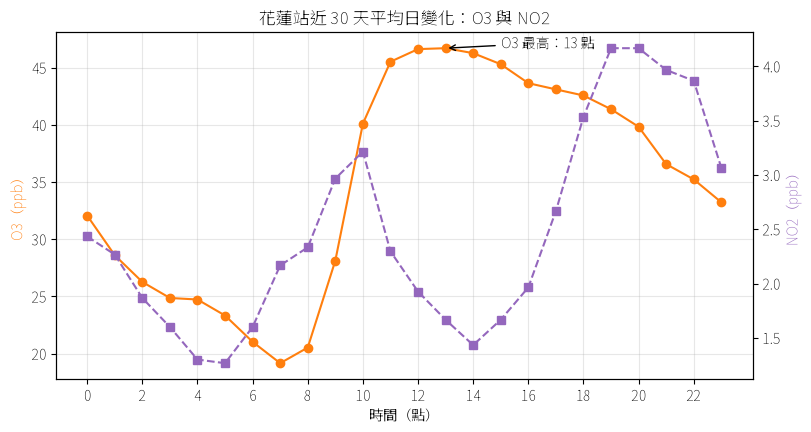

,o3,no2,nox,pm2.5
hour,,,,
0,32.1,2.4,3.4,9.1
1,28.6,2.3,3.3,8.3
2,26.3,1.9,2.9,9.1
3,24.9,1.6,2.6,8.8
4,24.7,1.3,2.2,8.1
5,23.3,1.3,2.2,7.8
6,21.0,1.6,2.6,8.0
7,19.2,2.2,3.4,8.3
8,20.5,2.3,3.9,8.3


In [15]:
#@title 🔑 參考解答：30 天平均日變化雙軸圖
di = clean.groupby('hour')[['o3', 'no2', 'nox', 'pm2.5']].mean()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(di.index, di['o3'], 'o-', color='tab:orange', label='O3')
ax.set_ylabel('O3（ppb）', color='tab:orange'); ax.set_xlabel('時間（點）'); ax.set_xticks(range(0, 24, 2))
ax2 = ax.twinx(); ax2.plot(di.index, di['no2'], 's--', color='tab:purple', label='NO2')
ax2.set_ylabel('NO2（ppb）', color='tab:purple')
pk = di['o3'].idxmax(); ax.annotate(f'O3 最高：{pk} 點', (pk, di['o3'].max()), xytext=(pk + 2, di['o3'].max()), arrowprops=dict(arrowstyle='->'))
ax.set_title('花蓮站近 30 天平均日變化：O3 與 NO2'); ax.grid(alpha=.3)
plt.savefig('fig3_日變化雙軸.png', dpi=200, bbox_inches='tight'); plt.show()
di.round(1)

## 步驟 5｜圖表優化與時空分析（小組討論，寫進學習單）
1. 花蓮的 **O₃ 最高值**通常出現在一天的**幾點**？最低在幾點？
2. **NO₂** 的高峰在幾點？和你想像的「早上上班尖峰」一樣嗎？
3. 這和課本講的**光照**、**NO₂ 光解**、**NO 滴定 O₃** 有什麼關聯？
4. 散佈圖的 r 很小，代表 NOx 和 O₃「沒關係」嗎？還有哪些因素（日照、風、傳輸）？

### 圖表校正檢核
- [ ] 標題說清楚「哪個測站、什麼期間、畫什麼」　- [ ] 軸標籤有**單位**（ppb、μg/m³）　- [ ] 中文沒有變成方塊　- [ ] 圖例顏色分得清楚

➡️ 課後學習單：[第 14 週 模組活動二](https://rlirdo.github.io/envchem-ai-module-kit/worksheets/W14_M2.html)

<sub>NDHU 自資系 游豐兆 博士生製作｜指導教授 楊悠娟 副教授｜國立東華大學 115-1 環境化學 × 生成式 AI 融入專業課程計畫</sub>